# Tutorial Topic 06 Set 01

In [3]:
library(tidyverse)
library(ggokabeito)

## Prepare these Exercises before Class

## In-Class Exercises

In [4]:
# Load the raw files
gdp   <- read_csv("../../../../data/gdp.csv")
urban <- read_csv("../../../../data/urban.csv")
pop   <- read_csv("../../../../data/pop.csv")
codes <- read_csv("../../../../data/country_to_continent.csv")

# Tidy GDP:
# the year is currently stored inside the column names,
# so we reshape to make year a variable
gdp <- gdp |>
  pivot_longer(
    cols = starts_with("gdp_pcap_pp_"),
    names_to = "year",
    names_pattern = "gdp_pcap_pp_(\\d{4})$",
    values_to = "gdp_pcap_pp"
  ) |>
  mutate(year = as.numeric(year))

# Tidy urbanisation:
# again, reshape so each row is one country-year
urban <- urban |>
  pivot_longer(
    cols = starts_with("urban"),
    names_to = "year",
    names_pattern = "urban_pct_(\\d{4})$",
    values_to = "urban_pct"
  ) |>
  mutate(year = as.numeric(year))

# Tidy population:
# this can be useful later for bubble size or weighted summaries
pop <- pop |>
  pivot_longer(
    cols = starts_with("pop"),
    names_to = "year",
    names_pattern = "pop_(\\d{4})$",
    values_to = "pop"
  ) |>
  mutate(year = as.numeric(year))

# Join the tidied files together.
# After this step, each row should represent one country-year.
analysis_df <- gdp |>
  left_join(
    urban |> select(-name),
    by = join_by(geo, year)
  ) |>
  left_join(
    pop |> select(-name),
    by = join_by(geo, year)
  ) |>
  left_join(
    codes |> select(-country_name),
    by = join_by(geo == iso3)
  )

# Check data coverage by year.
# This helps us see whether some years have much more missing data than others.
analysis_df |>
  group_by(year) |>
  summarise(
    n_rows = n(),
    pct_complete = mean(
      !is.na(gdp_pcap_pp) &
      !is.na(urban_pct) &
      !is.na(pop) &
      !is.na(continent_name)
    ) * 100
  )

# Suppose we decide that coverage is much better from 1960 onward.
# We can then restrict the time window and remove incomplete rows.
analysis_df <- analysis_df |>
  filter(between(year, 1960, 2020)) |>
  drop_na()

# Inspect the final analysis dataset
glimpse(analysis_df)

Rows: 193 Columns: 18
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (2): geo, name
dbl (16): gdp_pcap_pp_1950, gdp_pcap_pp_1955, gdp_pcap_pp_1960, gdp_pcap_pp_...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 193 Columns: 15
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (2): geo, name
dbl (13): urban_pct_1960, urban_pct_1965, urban_pct_1970, urban_pct_1975, ur...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 195 Columns: 18
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (2): geo, name
dbl (16): pop_1950, pop_1955, pop_1960, pop_1965, pop_1970, pop_1975, pop_19...

ℹ Use `spec()` to retrieve the full

year,n_rows,pct_complete
<dbl>,<int>,<dbl>
1950,200,0.0
1955,200,0.0
1960,200,99.5
1965,200,99.5
1970,200,99.5
1975,200,99.5
1980,200,99.5
1985,200,99.5
1990,200,99.5


Rows: 2,288
Columns: 8
$ geo            <chr> "AFG", "AFG", "AFG", "AFG", "AFG", "AFG", "AFG", "AFG",…
$ name           <chr> "Afghanistan", "Afghanistan", "Afghanistan", "Afghanist…
$ year           <dbl> 1960, 1965, 1970, 1975, 1980, 1985, 1990, 1995, 2000, 2…
$ gdp_pcap_pp    <dbl> 2277.640, 2359.717, 2477.913, 2228.086, 2251.285, 3068.…
$ urban_pct      <dbl> 8.401, 9.904, 11.643, 13.641, 15.995, 18.997, 21.177, 2…
$ pop            <dbl> 9035043, 10036008, 11290128, 12773954, 13169311, 114268…
$ continent_name <chr> "Asia", "Asia", "Asia", "Asia", "Asia", "Asia", "Asia",…
$ continent_code <chr> "AS", "AS", "AS", "AS", "AS", "AS", "AS", "AS", "AS", "…


### Exercise 7

In [6]:
options(repr.plot.width = 12, repr.plot.height = 10, repr.plot.res = 150)

Warning message:
“The following aesthetics were dropped during statistical transformation: size.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”
Warning message:
“The following aesthetics were dropped during statistical transformation: size.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”
Warning message:
“The following aesthetics were dropped during statistical transformation: size.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”


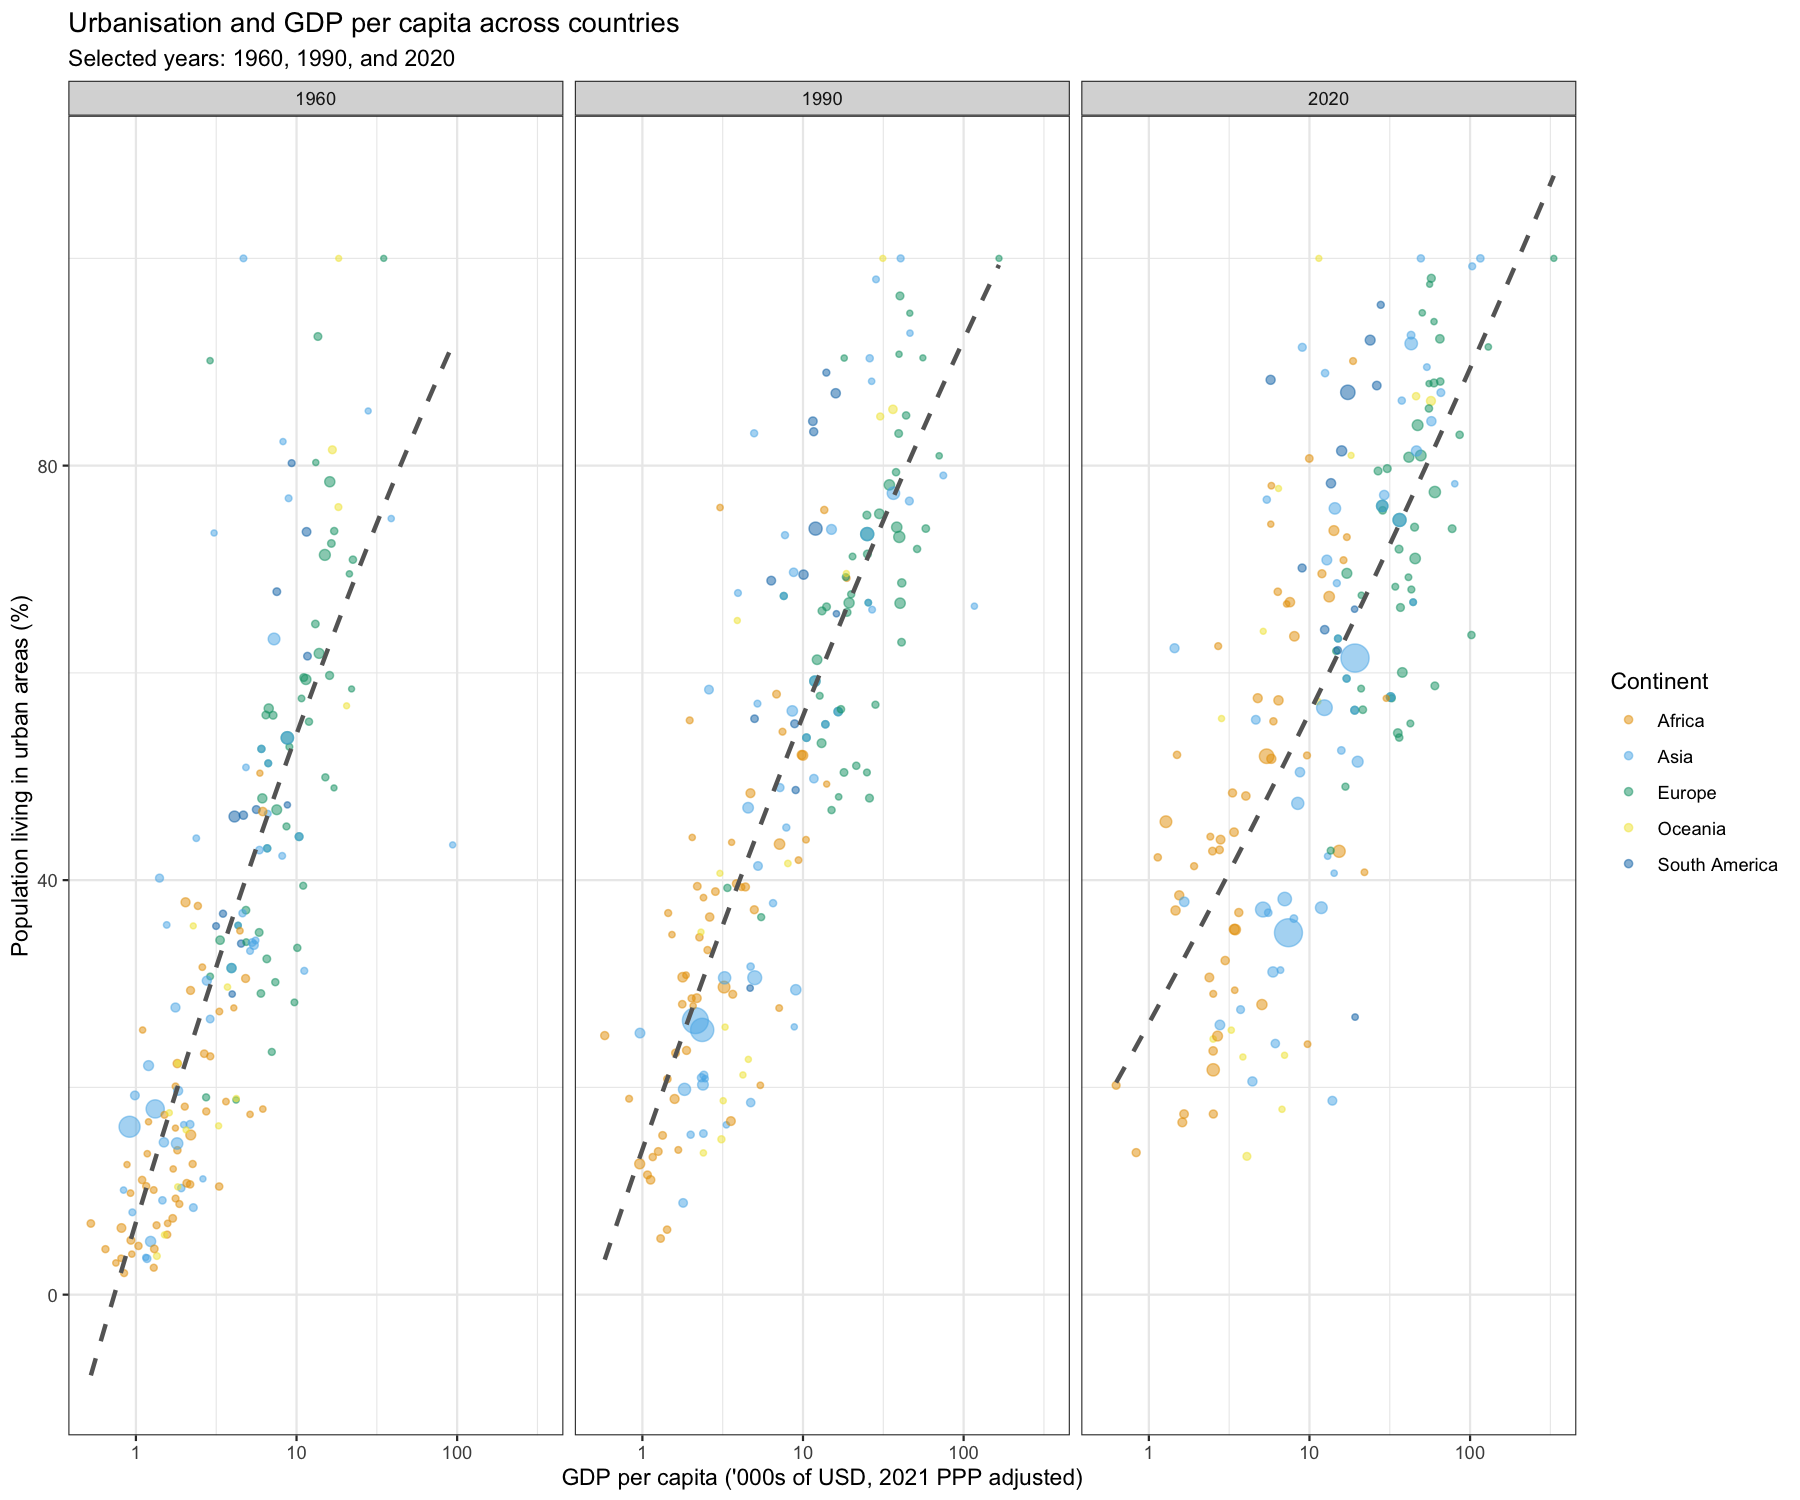

In [7]:
# Graph: relationship between GDP per capita and urbanisation
analysis_df |>
  filter(year %in% c(1960, 1990, 2020)) |>
  ggplot(
    aes(
      x = gdp_pcap_pp / 1e3,
      y = urban_pct,
      size = pop,
      colour = continent_name
    )
  ) +
  geom_point(alpha = 0.5) +
  geom_smooth(
    aes(x = gdp_pcap_pp / 1e3, y = urban_pct),
    method = "lm",
    formula = y ~ poly(x, 2),
    linetype = "dashed",
    se = FALSE,
    colour = "grey40"
  ) +
  scale_x_log10() +
  ggokabeito::scale_color_okabe_ito() +
  scale_size(guide = "none") +
  facet_wrap(~year) +
  labs(
    title = "Urbanisation and GDP per capita across countries",
    subtitle = "Selected years: 1960, 1990, and 2020",
    x = "GDP per capita ('000s of USD, 2021 PPP adjusted)",
    y = "Population living in urban areas (%)",
    colour = "Continent"
  ) +
  theme_bw()

In [9]:
# Table: continent-level summary for the same benchmark years
table_continent_year <- analysis_df |>
  filter(year %in% c(1960, 1990, 2020)) |>
  group_by(continent_name, year) |>
  summarise(
    avg_gdp_pcap_pp = weighted.mean(gdp_pcap_pp, w = pop, na.rm = TRUE),
    avg_urban_pct   = weighted.mean(urban_pct, w = pop, na.rm = TRUE),
    total_pop       = sum(pop, na.rm = TRUE),
    n_countries     = n_distinct(geo),
    .groups = "drop"
  ) |>
  mutate(
    avg_gdp_pcap_pp = round(avg_gdp_pcap_pp, 0),
    avg_urban_pct   = round(avg_urban_pct, 1),
    total_pop_m     = round(total_pop / 1e6, 1)
  ) |>
  select(
    continent = continent_name,
    year,
    n_countries,
    total_pop_m,
    avg_gdp_pcap_pp,
    avg_urban_pct
  ) |>
  arrange(continent, year)

table_continent_year |>
  knitr::kable(
    col.names = c(
      "Continent",
      "Year",
      "Countries",
      "Population (millions)",
      "Avg GDP per capita",
      "Avg urbanisation (%)"
    ),
    caption = "Urbanisation and GDP per capita by continent, 1960, 1990, and 2020"
  )



Table: Urbanisation and GDP per capita by continent, 1960, 1990, and 2020

|Continent     | Year| Countries| Population (millions)| Avg GDP per capita| Avg urbanisation (%)|
|:-------------|----:|---------:|---------------------:|------------------:|--------------------:|
|Africa        | 1960|        53|                 280.6|               2188|                 18.5|
|Africa        | 1990|        53|                 635.8|               3852|                 31.6|
|Africa        | 2020|        53|                1362.5|               5628|                 43.5|
|Asia          | 1960|        49|                1798.0|               2329|                 23.2|
|Asia          | 1990|        49|                3332.4|               5864|                 33.8|
|Asia          | 2020|        49|                4802.6|              15131|                 51.4|
|Europe        | 1960|        48|                 652.8|              10289|                 55.9|
|Europe        | 1990|        48